# 06 — Fine-tuning ResNet18 (N4), error analysis (N5), from-scratch control and Grad-CAM (N7)

**Idea.** In `05` every convolutional layer stayed frozen. Here we also unfreeze the **last residual block (`layer4`)** and train it with the head, so the highest-level features adapt to paintings. The early blocks (edges, textures) stay frozen: they are generic, and 1,050 images are too few to retrain 11 M parameters safely.

**Set-up (PLAN N4):** ImageNet weights, `layer4` + head trainable (8.4 M parameters), Adam with lr 1e-4 (small, so the pretrained weights are only nudged), augmentation (horizontal flip + light random crop, no colour jitter since colour is a style cue), early stopping on validation loss. Two input sizes, 3 seeds each:
- **128 px**: the native resolution of our images.
- **224 px**: upsampled to the ImageNet scale. It adds **no detail** (the pixels are interpolated), but the network's filters see objects at the size they were trained on.

Then: error analysis on validation (N5), ResNet18 trained **from random initialisation** (is the pretraining what matters?) and **Grad-CAM** (where does the network look?) (N7).

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch  # imported before scikit-learn: see tests/conftest.py
from torch import nn

FAST_RUN = os.environ.get("FAST_RUN") == "1"
FIG, CKPT = "../results/figures", "../checkpoints"
os.makedirs(CKPT, exist_ok=True)
torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True, "lines.linewidth": 2,
                     "font.size": 10, "axes.titlesize": 11, "legend.frameon": False})
print("FAST_RUN =", FAST_RUN)

FAST_RUN = False


In [2]:
import sys

sys.path.insert(0, "../src")
from museum.data import CLASSES, IMAGENET_MEAN, IMAGENET_STD, get_arrays, get_loaders
from museum.evaluation import benchmark_latency, model_size_mb, plot_confusion, save_result, total_parameters
from museum.models import TorchPredictor, build_resnet18, count_parameters
from museum.train import evaluate, fit, get_device, predict

device = get_device()
X_val, y_val = get_arrays(128, "val")
probe = build_resnet18(trainable="layer4")
print(f"device {device}; trainable parameters with layer4 + head: {count_parameters(probe):,} "
      f"of {total_parameters(probe):,}")

device mps; trainable parameters with layer4 + head: 8,396,293 of 11,179,077


## 1. Latency first

The architecture is the same as the frozen model, so the CPU cost depends only on the input size. We measure it **before** training, so that the selection rule below cannot be bent by the results.

**Selection rule:** highest mean validation accuracy over the 3 seeds among the input sizes whose 1-thread median latency is ≤ 40 ms; the seed-0 model is the candidate. If the difference between sizes is smaller than one seed standard deviation, the smaller (faster) input wins.

In [3]:
SIZES = [128, 224]
runs = 20 if FAST_RUN else 100
cpu_probe = build_resnet18(trainable="layer4").eval()
latency = {size: {f"threads_{t}": benchmark_latency(TorchPredictor(cpu_probe, size, IMAGENET_MEAN, IMAGENET_STD),
                                                    X_val[0], n_threads=t, runs=runs) for t in (1, 2)}
           for size in SIZES}
pd.DataFrame({s: {k: f"{v['median_ms']:.1f} (p95 {v['p95_ms']:.1f})" for k, v in lat.items()}
              for s, lat in latency.items()})

,128,224
threads_1,9.9 (p95 10.3),16.6 (p95 17.8)
threads_2,8.5 (p95 8.9),14.3 (p95 15.3)


## 2. Fine-tuning: 2 sizes × 3 seeds

Sanity check first: before any training, the new head is random, so the validation loss should be close to ln 5 ≈ 1.609 (chance level for 5 balanced classes) — not exactly, since the pretrained features are not centred.

In [4]:
SEEDS = [0] if FAST_RUN else [0, 1, 2]
N_EPOCHS = 2 if FAST_RUN else 40
PATIENCE = 5
loss_fn = nn.CrossEntropyLoss()


def run(size, seed, pretrained=True, trainable="layer4", lr=1e-4, n_epochs=N_EPOCHS, patience=PATIENCE):
    torch.manual_seed(seed)
    train_dl, val_dl, _, _ = get_loaders(img_size=size, batch_size=64, augment=True, normalize="imagenet", seed=seed)
    model = build_resnet18(pretrained=pretrained, trainable=trainable)
    initial_loss, _ = evaluate(model.to(device), val_dl, loss_fn, device)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    history = fit(model, train_dl, val_dl, loss_fn, optimizer, n_epochs, device, patience=patience,
                  track_grads=seed == 0, verbose=False)
    history["initial_val_loss"] = initial_loss
    return model, history, val_dl


runs_df, models, histories = [], {}, {}
for size in SIZES:
    for seed in SEEDS:
        model, hist, val_dl = run(size, seed)
        best = hist["best_epoch"] - 1
        models[(size, seed)], histories[(size, seed)] = model.cpu(), hist
        runs_df.append({"size": size, "seed": seed, "val_acc": hist["val_acc"][best], "val_loss": hist["val_loss"][best],
                        "best_epoch": hist["best_epoch"], "epochs_run": len(hist["val_loss"]),
                        "initial_val_loss": hist["initial_val_loss"], "train_time_s": sum(hist["epoch_time"])})
        print(f"{size} px seed {seed}: val acc {hist['val_acc'][best]:.3f} at epoch {hist['best_epoch']} "
              f"({sum(hist['epoch_time']):.0f} s)")
runs_df = pd.DataFrame(runs_df)
assert (runs_df.initial_val_loss.between(1.0, 3.0)).all(), "untrained head should be near chance"
runs_df.round(3)

128 px seed 0: val acc 0.840 at epoch 10 (31 s)


128 px seed 1: val acc 0.827 at epoch 7 (19 s)


128 px seed 2: val acc 0.827 at epoch 8 (21 s)


224 px seed 0: val acc 0.862 at epoch 11 (78 s)


224 px seed 1: val acc 0.902 at epoch 9 (62 s)


224 px seed 2: val acc 0.884 at epoch 12 (89 s)


,size,seed,val_acc,val_loss,best_epoch,epochs_run,initial_val_loss,train_time_s
0,128,0,0.840,0.513,10,15,1.916,31.348
1,128,1,0.827,0.489,7,12,1.818,19.186
2,128,2,0.827,0.542,8,13,1.933,20.650
3,224,0,0.862,0.366,11,16,1.658,77.523
4,224,1,0.902,0.348,9,14,1.652,61.734
5,224,2,0.884,0.370,12,17,1.735,88.666


In [5]:
agg = runs_df.groupby("size").agg(val_acc_mean=("val_acc", "mean"), val_acc_std=("val_acc", "std"),
                                  best_epoch=("best_epoch", "mean"), train_time_s=("train_time_s", "mean"))
agg["latency_1t_ms"] = [latency[s]["threads_1"]["median_ms"] for s in agg.index]
agg["latency_ok"] = agg.latency_1t_ms <= 40
agg.round(3)

,val_acc_mean,val_acc_std,best_epoch,train_time_s,latency_1t_ms,latency_ok
size,,,,,,
128,0.831,0.008,8.333,23.728,9.912,True
224,0.883,0.020,10.667,75.974,16.620,True


In [6]:
ok = agg[agg.latency_ok]
SIZE = int(ok.val_acc_mean.idxmax())
other = [s for s in ok.index if s != SIZE]
if other and ok.val_acc_mean[SIZE] - ok.val_acc_mean[other[0]] < np.nan_to_num(ok.val_acc_std.max()):
    SIZE = int(min(SIZE, other[0]))  # the gap is within seed noise: the faster input wins
print(f"chosen input size: {SIZE} px; candidate = seed 0 at {SIZE} px")

chosen input size: 224 px; candidate = seed 0 at 224 px


## 3. Training monitoring

Loss and accuracy per epoch for seed 0 at both sizes, and the gradient norm of the trainable weights (the head and the last convolution of `layer4`). The vertical line is the epoch whose weights early stopping restored.

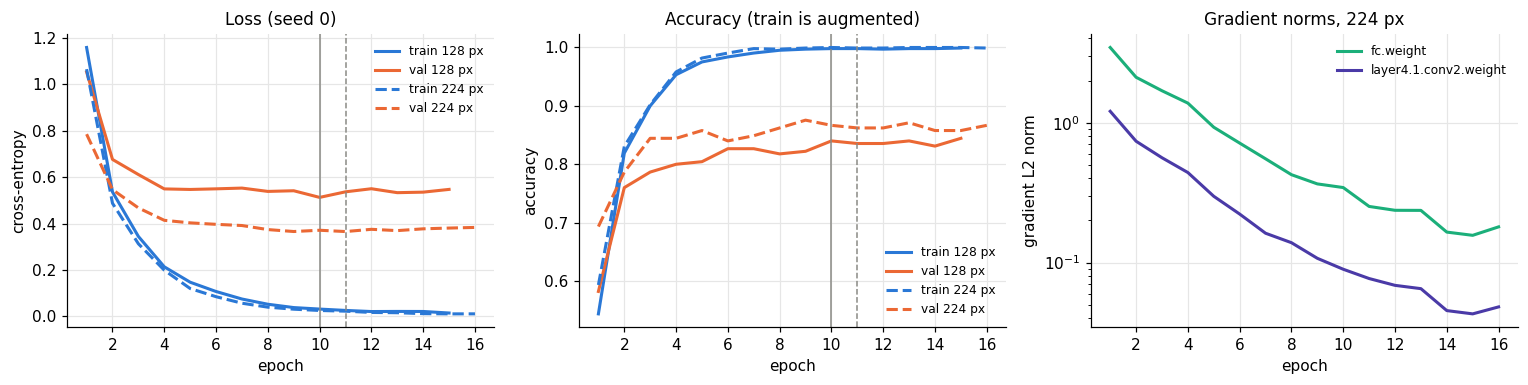

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for size, style in zip(SIZES, ["-", "--"], strict=True):
    hist = histories[(size, 0)]
    ep = np.arange(1, len(hist["train_loss"]) + 1)
    axes[0].plot(ep, hist["train_loss"], color="#2a78d6", linestyle=style, label=f"train {size} px")
    axes[0].plot(ep, hist["val_loss"], color="#eb6834", linestyle=style, label=f"val {size} px")
    axes[1].plot(ep, hist["train_acc"], color="#2a78d6", linestyle=style, label=f"train {size} px")
    axes[1].plot(ep, hist["val_acc"], color="#eb6834", linestyle=style, label=f"val {size} px")
    for ax in axes[:2]:
        ax.axvline(hist["best_epoch"], color="#8a8a85", linewidth=1, linestyle=style)
hist = histories[(SIZE, 0)]
ep = np.arange(1, len(hist["grad_norms"]) + 1)
for name, color in (("net.fc.weight", "#1baf7a"), ("net.layer4.1.conv2.weight", "#4a3aa7")):
    axes[2].plot(ep, [g[name] for g in hist["grad_norms"]], color=color, label=name.replace("net.", ""))
axes[0].set(xlabel="epoch", ylabel="cross-entropy", title="Loss (seed 0)")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy (train is augmented)")
axes[2].set(xlabel="epoch", ylabel="gradient L2 norm", title=f"Gradient norms, {SIZE} px", yscale="log")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{FIG}/resnet_finetune_curves.png", bbox_inches="tight")
plt.show()

## 4. Error analysis on validation (N5)

The test set stays untouched until `07_comparison`; the error analysis uses validation.

In [8]:
candidate = models[(SIZE, 0)]
_, val_dl, _, _ = get_loaders(img_size=SIZE, batch_size=64, normalize="imagenet")
y_true, y_pred, probs = predict(candidate.to(device), val_dl, device)
val_acc = float((y_true == y_pred).mean())
end_to_end = TorchPredictor(candidate, SIZE, IMAGENET_MEAN, IMAGENET_STD, device=device).predict(X_val)
assert (end_to_end == y_pred).mean() > 0.99, "raw-image predictor must match the loader pipeline"
print(f"fine-tuned candidate ({SIZE} px, seed 0): val acc {val_acc:.3f}")
plot_confusion(y_true, y_pred, CLASSES, f"{FIG}/resnet_finetune_val_confusion.png",
               title=f"Fine-tuned ResNet18, {SIZE} px (validation)")
pd.DataFrame({"recall": [(y_pred[y_true == k] == k).mean() for k in range(5)]}, index=CLASSES).T.round(2)

fine-tuned candidate (224 px, seed 0): val acc 0.862


,Baroque,Cubism,Impressionism,Pop_Art,Ukiyo_e
recall,0.8,0.82,0.91,0.82,0.96


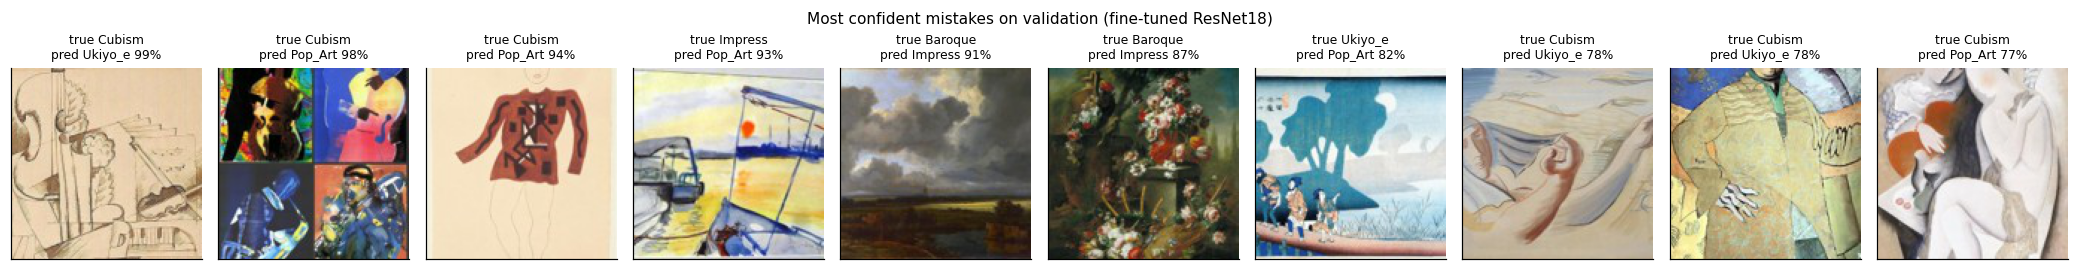

In [9]:
wrong = np.flatnonzero(y_pred != y_true)
wrong = wrong[np.argsort(-probs[wrong].max(1))][:10]
fig, axes = plt.subplots(1, max(len(wrong), 1), figsize=(1.9 * max(len(wrong), 1), 2.6), squeeze=False)
for ax, k in zip(axes[0], wrong, strict=False):
    ax.imshow(X_val[k])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"true {CLASSES[y_true[k]][:7]}\npred {CLASSES[y_pred[k]][:7]} {probs[k].max():.0%}", fontsize=8)
fig.suptitle("Most confident mistakes on validation (fine-tuned ResNet18)", fontsize=10)
fig.tight_layout()
fig.savefig(f"{FIG}/resnet_finetune_confident_mistakes.png", bbox_inches="tight")
plt.show()

## 5. Control: the same ResNet18 trained from random initialisation (N7)

Same architecture, same data and augmentation, but **no ImageNet weights** and every layer trainable (lr 1e-3, the usual rate from scratch, longer patience). If it does much worse, the accuracy of the fine-tuned model comes from the pretraining, not from the architecture.

from scratch, 128 px: val acc 0.524 at epoch 11 (86 s); pretrained + fine-tuned: 0.831 (mean of seeds)


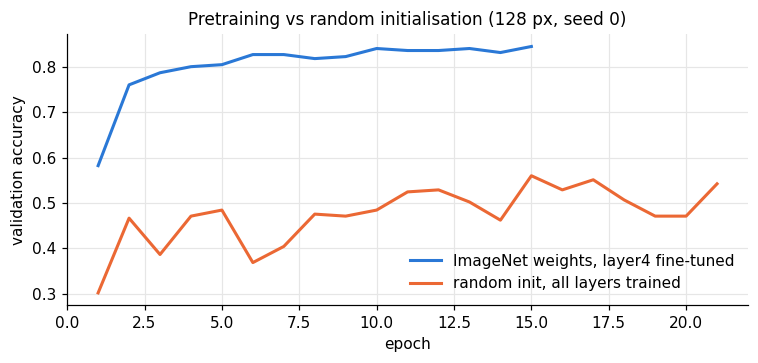

In [10]:
scratch, scratch_hist, _ = run(128, 0, pretrained=False, trainable="all", lr=1e-3,
                               n_epochs=2 if FAST_RUN else 80, patience=10)
best = scratch_hist["best_epoch"] - 1
scratch_acc = scratch_hist["val_acc"][best]
print(f"from scratch, 128 px: val acc {scratch_acc:.3f} at epoch {scratch_hist['best_epoch']} "
      f"({sum(scratch_hist['epoch_time']):.0f} s); pretrained + fine-tuned: {agg.val_acc_mean[128]:.3f} (mean of seeds)")

fig, ax = plt.subplots(figsize=(7, 3.4))
for hist, color, label in ((histories[(128, 0)], "#2a78d6", "ImageNet weights, layer4 fine-tuned"),
                           (scratch_hist, "#eb6834", "random init, all layers trained")):
    ax.plot(np.arange(1, len(hist["val_acc"]) + 1), hist["val_acc"], color=color, label=label)
ax.set(xlabel="epoch", ylabel="validation accuracy", title="Pretraining vs random initialisation (128 px, seed 0)")
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG}/resnet_scratch_vs_pretrained.png", bbox_inches="tight")
plt.show()

## 6. Grad-CAM: where does the fine-tuned network look? (N7)

Grad-CAM weights each of the 512 feature maps of `layer4` by the average gradient of the predicted class score with respect to it, sums them, keeps the positive part and upsamples it onto the image. Bright = regions that pushed the prediction up. Two validation images per style.

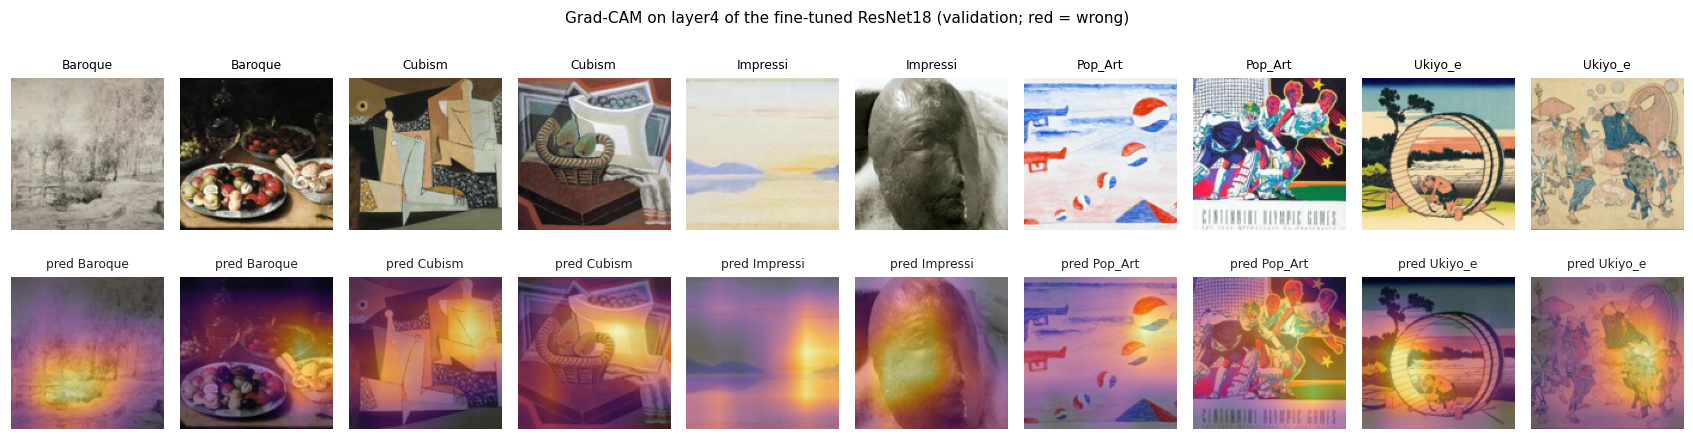

In [11]:
def grad_cam(model, x):
    store = {}

    def keep(module, inputs, out):  # returns None, so the layer output is left unchanged
        store["act"] = out
        out.register_hook(lambda grad: store.update(grad=grad))

    handle = model.net.layer4.register_forward_hook(keep)
    model.eval()
    logits = model(x)
    pred = logits.argmax(1)
    model.zero_grad()
    logits[torch.arange(len(x)), pred].sum().backward()
    handle.remove()
    weights = store["grad"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * store["act"]).sum(1, keepdim=True))
    cam = nn.functional.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
    return cam.detach().numpy(), pred.numpy()


cam_model = candidate.cpu()
picked = np.concatenate([np.flatnonzero(y_val == k)[:2] for k in range(5)])
x = TorchPredictor(cam_model, SIZE, IMAGENET_MEAN, IMAGENET_STD).to_tensor(X_val[picked])
cams, cam_pred = grad_cam(cam_model, x)
fig, axes = plt.subplots(2, len(picked), figsize=(1.55 * len(picked), 4.3))
for col, (k, cam, p) in enumerate(zip(picked, cams, cam_pred, strict=True)):
    axes[0, col].imshow(X_val[k])
    axes[0, col].set_title(CLASSES[y_val[k]][:8], fontsize=8)
    axes[1, col].imshow(np.asarray(X_val[k]), alpha=1.0)
    axes[1, col].imshow(nn.functional.interpolate(torch.as_tensor(cam)[None, None], size=(128, 128),
                                                  mode="bilinear")[0, 0], cmap="inferno", alpha=0.55)
    axes[1, col].set_title(f"pred {CLASSES[p][:8]}", fontsize=8, color="#1f2328" if p == y_val[k] else "#e34948")
    for ax in axes[:, col]:
        ax.axis("off")
fig.suptitle("Grad-CAM on layer4 of the fine-tuned ResNet18 (validation; red = wrong)", fontsize=10)
fig.tight_layout(h_pad=1.5)
fig.savefig(f"{FIG}/resnet_gradcam.png", bbox_inches="tight")
plt.show()

## 7. Freezing the fine-tuned candidate

In [12]:
torch.save({"state_dict": candidate.state_dict(), "img_size": SIZE, "trainable": "layer4"}, f"{CKPT}/resnet_finetune.pt")
path = save_result("resnet_finetune", {
    "config": {"img_size": SIZE, "trainable": "layer4 + fc", "optimizer": "Adam", "lr": 1e-4, "batch_size": 64,
               "augment": "hflip + RandomResizedCrop(0.8-1.0)", "max_epochs": N_EPOCHS, "patience": PATIENCE,
               "normalize": "imagenet", "weights": "IMAGENET1K_V1", "seed": 0, "seeds": SEEDS,
               "trainable_params": count_parameters(candidate),
               "val_acc_by_size": {int(s): {"mean": float(r.val_acc_mean), "std": float(np.nan_to_num(r.val_acc_std))}
                                   for s, r in agg.iterrows()},
               "from_scratch_val_acc_128": float(scratch_acc), "fast_run": FAST_RUN},
    "val_acc": val_acc, "n_params": total_parameters(candidate), "size_mb": model_size_mb(f"{CKPT}/resnet_finetune.pt"),
    "latency_ms": latency[SIZE],
    "train_time_s": float(runs_df[(runs_df["size"] == SIZE) & (runs_df.seed == 0)].train_time_s.iloc[0]),
})
print("wrote", path.relative_to(path.parents[1]))

wrote results/resnet_finetune.json


## What we see

All numbers are on validation (225 images, 45 per style); the test set is used once, in `07_comparison`.

- **Fine-tuned vs frozen.** Unfreezing `layer4` raises the mean validation accuracy at 224 px to **0.883 ± 0.020** (3 seeds), against 0.834 ± 0.018 for the frozen features with an `nn.Linear` head and 0.840 for the frozen candidate (`results/resnet_frozen.json`). The gain (about 0.05) is larger than the seed spread, so adapting the last block helps. The candidate itself is seed 0, fixed before training by the selection rule, and it is the weakest of the three seeds (0.862, against 0.902 and 0.884). Its lead over the frozen candidate is 0.022, i.e. 5 images out of 225, within noise: whether it is really better is settled on the test set in `07`. Latency and size are the same as the frozen model (same architecture: 16.6 ms median on 1 CPU thread, 44.8 MB); only the training is longer (about 75 s per run on `mps`, against a few seconds for a head on cached features).
- **128 vs 224 px.** 224 px wins clearly, 0.883 ± 0.020 against 0.831 ± 0.008. The gap is larger than the seed std, so the rule picks 224 px. Upsampling adds no information, so the gain comes from the pretrained filters seeing objects at the ImageNet scale (the same effect as in `05`). The cost is a 1-thread latency of 16.6 ms instead of 9.9 ms, well inside the 40 ms budget.
- **Monitoring.** The initial validation loss is 1.65–1.93, close to ln 5 ≈ 1.61: a random head, as expected (slightly above at 128 px because the features are not centred). The training accuracy reaches about 1.0 by epoch 8 while the validation accuracy plateaus near 0.86 (seed 0, 224 px): the network memorises the 1,050 training images. The validation loss does not climb much, though: it flattens after epoch 9, and early stopping restored epoch 11 (224 px) and 10 (128 px), stopping 5 epochs later. The gradient norms of the head and of the last `layer4` convolution decrease smoothly by about one order of magnitude: no explosion, no vanishing.
- **Errors (N5).** Recall per style: Ukiyo-e 0.96, Impressionism 0.91, Cubism 0.82, Pop Art 0.82, Baroque 0.80. Six of the ten most confident mistakes are Cubist works, and they share a medium rather than a style: pencil sketches on beige paper are taken for Ukiyo-e (paper tone, line drawing), flat saturated colour fields for Pop Art. The two Baroque errors are a cloudy landscape and a flower piece predicted Impressionism, i.e. subjects typical of Impressionism. The network leans on palette, medium and subject, which is a real limit for a museum guide (a Cubist drawing is not a print).
- **From scratch (N7).** The same ResNet18 trained from random initialisation on 128 px reaches **0.524** (best epoch 11, noisy curve), against 0.831 for the pretrained, fine-tuned model at the same size. About 30 points of accuracy come from the ImageNet pretraining: with 1,050 images, 11 M parameters cannot be learned from zero.
- **Grad-CAM (N7).** All ten examples are classified correctly. On most of them the heat concentrates on one salient region rather than spreading over the painted surface: the fruit and mushrooms of the Baroque still life, the basket in the Cubist one, the face, the Pepsi logos, the figure inside the barrel in the Ukiyo-e print, the bright horizon of the Impressionist sea. So on these examples the network mostly looks at the subject. Grad-CAM shows *where* it looks, not *what* it uses there (shape, brushwork or colour), and ten images are illustrations, not evidence.

**Candidate frozen:** fine-tuned ResNet18, 224 px, seed 0, `checkpoints/resnet_finetune.pt` (not committed), summary in `results/resnet_finetune.json`.